# Task 3: Sentiment & Stock Return Correlation

Align FNSPID news headlines with daily stock returns and measure Pearson correlation.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def find_project_root() -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "src" / "correlation.py").exists():
            return candidate
    raise FileNotFoundError("Could not find project root (missing src/correlation.py)")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from correlation import align_sentiment_and_returns, summarize_correlations
from data_loader import NewsDataLoader, StockDataLoader
from sentiment import aggregate_daily_sentiment, score_dataframe

TICKER = "AAPL"

## 1. Load and prepare news data

In [3]:
news_loader = NewsDataLoader(PROJECT_ROOT / "data/raw/raw_analyst_ratings.csv")
news_df = news_loader.load()
news_df = news_loader.filter_by_ticker(news_df, TICKER)
news_df.head()

,Unnamed: 0,headline,url,publisher,date,stock,trading_date
6680,7120,Tech Stocks And FAANGS Strong Again To Start D...,https://www.benzinga.com/government/20/06/1622...,JJ Kinahan,2020-06-10 15:33:26+00:00,AAPL,2020-06-10
6681,7121,10 Biggest Price Target Changes For Wednesday,https://www.benzinga.com/analyst-ratings/price...,Lisa Levin,2020-06-10 12:14:08+00:00,AAPL,2020-06-10
6682,7122,"Benzinga Pro's Top 5 Stocks To Watch For Wed.,...",https://www.benzinga.com/short-sellers/20/06/1...,Benzinga Newsdesk,2020-06-10 11:53:47+00:00,AAPL,2020-06-10
6683,7123,"Deutsche Bank Maintains Buy on Apple, Raises P...",https://www.benzinga.com/news/20/06/16219873/d...,Benzinga Newsdesk,2020-06-10 11:19:25+00:00,AAPL,2020-06-10
6684,7124,Apple To Let Users Trade In Their Mac Computer...,https://www.benzinga.com/news/20/06/16218697/a...,Neer Varshney,2020-06-10 10:27:11+00:00,AAPL,2020-06-10


## 2. Sentiment analysis on headlines

In [4]:
scored_news = score_dataframe(news_df)
daily_sentiment = aggregate_daily_sentiment(scored_news)
daily_sentiment.head()

,avg_sentiment,article_count
date,,
2020-03-08,-0.155556,3
2020-03-09,0.021708,8
2020-03-10,0.018624,14
2020-03-11,-0.083048,5
2020-03-12,0.069215,11


## 3. Load stock prices and compute daily returns

In [5]:
stock_loader = StockDataLoader(PROJECT_ROOT / "data/stocks")
stock_df = stock_loader.load(TICKER)
stock_df.head()

Price,Open,High,Low,Close,Volume
Date,,,,,
2026-06-24,295.359985,299.700012,292.940002,293.079987,53081900
2026-06-25,287.399994,288.799988,273.750000,275.149994,107013700
2026-06-26,275.000000,285.950012,274.209991,283.779999,261775500
2026-06-29,286.730011,288.369995,279.850006,281.739990,66427000
2026-06-30,281.170013,289.940002,280.700012,289.359985,65100200


## 4. Date alignment and correlation analysis

In [6]:
merged = align_sentiment_and_returns(daily_sentiment, stock_df)
correlations = summarize_correlations(merged)

for name, value in correlations.items():
    print(f"{name}: {value:.4f}")

sentiment_vs_same_day_return: nan
sentiment_vs_next_day_return: nan
lagged_sentiment_vs_return: nan


/home/ruhama/Desktop/sentiment-analysis-week2/venv/lib/python3.13/site-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
/home/ruhama/Desktop/sentiment-analysis-week2/venv/lib/python3.13/site-packages/seaborn/matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


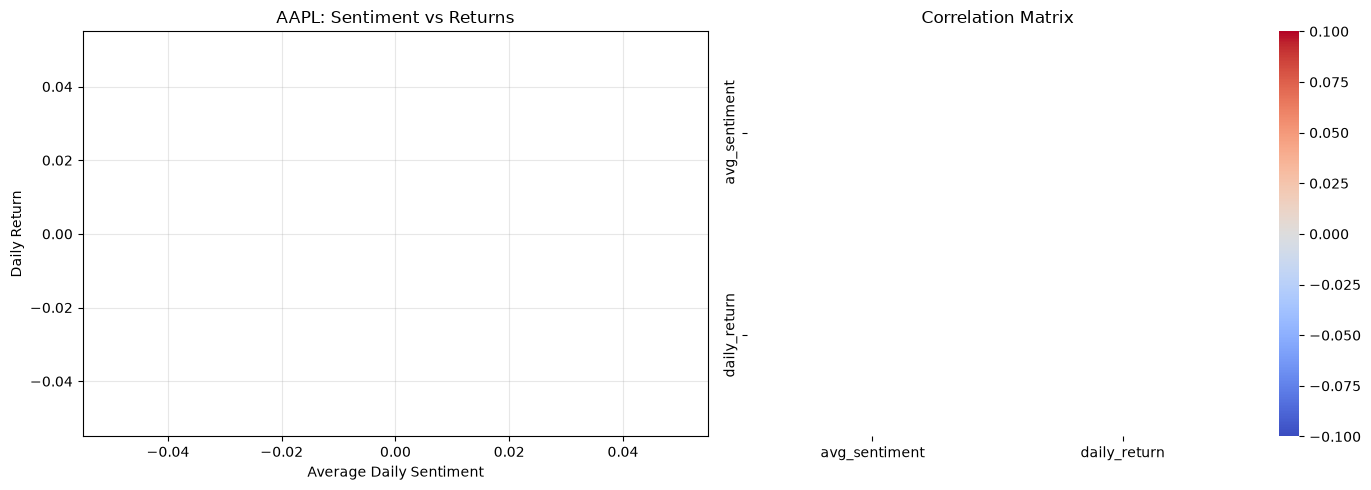

In [7]:
plot_df = merged[["avg_sentiment", "daily_return"]].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(plot_df["avg_sentiment"], plot_df["daily_return"], alpha=0.5)
axes[0].set_xlabel("Average Daily Sentiment")
axes[0].set_ylabel("Daily Return")
axes[0].set_title(f"{TICKER}: Sentiment vs Returns")
axes[0].grid(True, alpha=0.3)

corr_matrix = plot_df.corr(method="pearson")
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlation Matrix")
plt.tight_layout()
plt.show()